# Classification from Scratch V2.1 (NumPy only) — Response, FT-Transformer-lite, k=5

**Version:** V2.1. **Role:** mandatory from-scratch twin of `classification_pytorch_V2_1.ipynb` — no
torch. `sklearn` ONLY for split/scaler/metrics. Same tokenizer+CLS+2-block architecture and hypers as
`classification_scratch_V2_0.ipynb`, copied verbatim and wrapped in the same 5-fold `StratifiedKFold`
loop the oracle used. The numeric grad-check runs once (architecture-only) rather than per fold.
Weights → `./weights_V2_1/classification_scratch_kfold_metrics.json`.

In [1]:
import json, os
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

assert os.path.exists("weights_V2_1/classification_pytorch_kfold_metrics.json"), "oracle must run first"
SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V2_1", exist_ok=True)

## 1. LOAD DATA (identical to V2.0)

In [2]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
CLF_NUMERIC = ["AcceptedCmp5","AcceptedCmp3","MntWines","MntMeatProducts","NumCatalogPurchases",
    "Recency","Customer_Tenure_Days","MntGoldProds","Income","MntFruits","AcceptedCmp1",
    "AcceptedCmp2","NumWebPurchases","MntSweetProducts","MntFishProducts","NumStorePurchases","Age"]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
inc_idx = FEATURE_COLS.index("Income")
IN_DIM, D, H, DK, FF, LAYERS, P = len(FEATURE_COLS), 32, 4, 8, 64, 2, 0.1
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {IN_DIM} dims | d={D} L={LAYERS} H={H} p={P}")

features: 17 numeric + 5 dummies = 22 dims | d=32 L=2 H=4 p=0.1


## 2. params + forward/backward helpers (identical to V2.0)

In [3]:
EPS = 1e-5
def ln_fwd(x, g, b):
    mu = x.mean(-1, keepdims=True); xc = x - mu
    var = (xc ** 2).mean(-1, keepdims=True)
    xh = xc / np.sqrt(var + EPS); y = xh * g + b
    return y, (x, xh, xc, var, g)
def ln_bwd(dy, c):
    x, xh, xc, var, g = c; N = x.shape[-1]; iv = 1.0 / np.sqrt(var + EPS)
    dxh = dy * g
    dvar = (dxh * xc * -0.5 * (var + EPS) ** (-1.5)).sum(-1, keepdims=True)
    dmu = (-dxh * iv).sum(-1, keepdims=True) + dvar * (-2.0 * xc).mean(-1, keepdims=True)
    dx = dxh * iv + dvar * 2.0 * xc / N + dmu / N
    return dx, (dy * xh).sum(tuple(range(dy.ndim - 1))), dy.sum(tuple(range(dy.ndim - 1)))
def lin_fwd(x, W, b): return x @ W + b
def dropout_fwd(x, train):
    if not train: return x, None
    m = (drop_rng.rand(*x.shape) > P) / (1.0 - P); return x * m, m
def softmax_fwd(s):
    e = np.exp(s - s.max(-1, keepdims=True)); return e / e.sum(-1, keepdims=True)
def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

def block_fwd(t, l, train):
    y1, c1 = ln_fwd(t, P_[f"g1{l}"], P_[f"b1{l}"]); B, T, Dd = y1.shape
    Q = lin_fwd(y1, P_[f"Wq{l}"], P_[f"bq{l}"]); K = lin_fwd(y1, P_[f"Wk{l}"], P_[f"bk{l}"]); V = lin_fwd(y1, P_[f"Wv{l}"], P_[f"bv{l}"])
    Q4 = Q.reshape(B, T, H, DK).transpose(0, 2, 1, 3); K4 = K.reshape(B, T, H, DK).transpose(0, 2, 1, 3); V4 = V.reshape(B, T, H, DK).transpose(0, 2, 1, 3)
    S = (Q4 @ K4.transpose(0, 1, 3, 2)) / np.sqrt(DK); Pb = softmax_fwd(S)
    Pm, dmask = dropout_fwd(Pb, train)
    O4 = Pm @ V4; O = O4.transpose(0, 2, 1, 3).reshape(B, T, Dd)
    u = t + lin_fwd(O, P_[f"Wo{l}"], P_[f"bo{l}"])
    y2, c2 = ln_fwd(u, P_[f"g2{l}"], P_[f"b2{l}"])
    h1 = lin_fwd(y2, P_[f"F1{l}"], P_[f"f1b{l}"]); a1 = np.maximum(h1, 0); ad, amask = dropout_fwd(a1, train)
    f = lin_fwd(ad, P_[f"F2{l}"], P_[f"f2b{l}"]); v = u + f
    return v, {"t": t, "y1": y1, "c1": c1, "Q4": Q4, "K4": K4, "V4": V4, "S": S, "Pb": Pb, "Pm": Pm,
               "dmask": dmask, "O": O, "u": u, "y2": y2, "c2": c2, "h1": h1, "amask": amask, "ad": ad, "l": l}

def block_bwd(dv, c, G):
    l = c["l"]; y1, Q4, K4, V4, Pb, Pm = c["y1"], c["Q4"], c["K4"], c["V4"], c["Pb"], c["Pm"]
    B, T, Dd = y1.shape
    df = dv.copy(); du_res = dv.copy()
    d_ad = df @ P_[f"F2{l}"].T; G[f"F2{l}"] += c["ad"].reshape(-1, FF).T @ df.reshape(-1, Dd); G[f"f2b{l}"] += df.sum((0, 1))
    if c["amask"] is not None: d_ad = d_ad * c["amask"]
    d_h1 = d_ad * (c["h1"] > 0)
    d_y2 = d_h1 @ P_[f"F1{l}"].T; G[f"F1{l}"] += c["y2"].reshape(-1, Dd).T @ d_h1.reshape(-1, FF); G[f"f1b{l}"] += d_h1.sum((0, 1))
    du_ffn, dg2, db2 = ln_bwd(d_y2, c["c2"]); G[f"g2{l}"] += dg2; G[f"b2{l}"] += db2
    du = du_res + du_ffn
    dt_res = du.copy()
    d_O = du @ P_[f"Wo{l}"].T; G[f"Wo{l}"] += c["O"].reshape(-1, Dd).T @ du.reshape(-1, Dd); G[f"bo{l}"] += du.sum((0, 1))
    dO4 = d_O.reshape(B, T, H, DK).transpose(0, 2, 1, 3)
    dV4 = np.matmul(Pm.transpose(0, 1, 3, 2), dO4)
    dPm = np.matmul(dO4, V4.transpose(0, 1, 3, 2))
    dPm = dPm * c["dmask"] if c["dmask"] is not None else dPm
    dS = Pb * (dPm - (dPm * Pb).sum(-1, keepdims=True))
    dS = dS / np.sqrt(DK)
    dQ4 = np.matmul(dS, K4); dK4 = np.matmul(dS.transpose(0, 1, 3, 2), Q4)
    dQ = dQ4.transpose(0, 2, 1, 3).reshape(B, T, Dd); dK = dK4.transpose(0, 2, 1, 3).reshape(B, T, Dd)
    dV = dV4.transpose(0, 2, 1, 3).reshape(B, T, Dd)
    d_y1 = dQ @ P_[f"Wq{l}"].T + dK @ P_[f"Wk{l}"].T + dV @ P_[f"Wv{l}"].T
    G[f"Wq{l}"] += y1.reshape(-1, Dd).T @ dQ.reshape(-1, Dd); G[f"bq{l}"] += dQ.sum((0, 1))
    G[f"Wk{l}"] += y1.reshape(-1, Dd).T @ dK.reshape(-1, Dd); G[f"bk{l}"] += dK.sum((0, 1))
    G[f"Wv{l}"] += y1.reshape(-1, Dd).T @ dV.reshape(-1, Dd); G[f"bv{l}"] += dV.sum((0, 1))
    dt_mhsa, dg1, db1 = ln_bwd(d_y1, c["c1"]); G[f"g1{l}"] += dg1; G[f"b1{l}"] += db1
    return dt_res + dt_mhsa

def model_fwd(Xb, train):
    B = Xb.shape[0]
    toks = [Xb[:, j:j+1] @ P_["tokW"][j:j+1, :] + P_["tokb"][j:j+1, :] for j in range(IN_DIM)]
    t = np.stack(toks, axis=1)
    t = np.concatenate([np.broadcast_to(P_["cls"], (B, 1, D)), t], axis=1)
    caches = []
    for l in range(LAYERS):
        t, c = block_fwd(t, l, train); caches.append(c)
    yf, cf = ln_fwd(t[:, 0], P_["gf"], P_["bf"])
    logit = yf @ P_["Wh"] + P_["bh"]
    return logit, (Xb, caches, yf, cf)

def model_bwd(dlogit, cache, G):
    Xb, caches, yf, cf = cache
    G["Wh"] += yf.T @ dlogit; G["bh"] += dlogit.sum(0)
    d_yf = dlogit @ P_["Wh"].T
    d_cls, dg, db = ln_bwd(d_yf, cf); G["gf"] += dg; G["bf"] += db
    B = Xb.shape[0]; dt = np.zeros((B, 1 + IN_DIM, D))
    dt[:, 0] = d_cls
    for l in reversed(range(LAYERS)):
        dt = block_bwd(dt, caches[l], G)
    G["cls"] += dt[:, 0].sum(0)
    dTok = dt[:, 1:]
    for j in range(IN_DIM):
        G["tokW"][j:j+1, :] += (Xb[:, j:j+1].T @ dTok[:, j, :])
        G["tokb"][j:j+1, :] += dTok[:, j, :].sum(0, keepdims=True)

def fwd_loss(Xb, yb, train, weighted):
    logit, cache = model_fwd(Xb, train)
    p = sigmoid(logit).ravel(); y = yb.ravel(); B = len(y)
    eps = 1e-12; pc = np.clip(p, eps, 1 - eps)
    if weighted:
        loss = -(PW * y * np.log(pc) + (1 - y) * np.log(1 - pc)).mean()
        dlogit = ((p + p * y * (PW - 1) - PW * y) / B).reshape(-1, 1)
    else:
        loss = -(y * np.log(pc) + (1 - y) * np.log(1 - pc)).mean()
        dlogit = ((p - y) / B).reshape(-1, 1)
    return loss, dlogit, logit, cache, p

def new_params():
    Pp = {}
    Pp["tokW"] = np.random.randn(IN_DIM, D) * np.sqrt(2.0 / 1.0)
    Pp["tokb"] = np.zeros((IN_DIM, D))
    Pp["cls"] = np.random.randn(D) * 0.02
    for l in range(LAYERS):
        Pp[f"Wq{l}"] = np.random.randn(D, D) * np.sqrt(2.0 / D); Pp[f"bq{l}"] = np.zeros(D)
        Pp[f"Wk{l}"] = np.random.randn(D, D) * np.sqrt(2.0 / D); Pp[f"bk{l}"] = np.zeros(D)
        Pp[f"Wv{l}"] = np.random.randn(D, D) * np.sqrt(2.0 / D); Pp[f"bv{l}"] = np.zeros(D)
        Pp[f"Wo{l}"] = np.random.randn(D, D) * np.sqrt(2.0 / D); Pp[f"bo{l}"] = np.zeros(D)
        Pp[f"F1{l}"] = np.random.randn(D, FF) * np.sqrt(2.0 / D); Pp[f"f1b{l}"] = np.zeros(FF)
        Pp[f"F2{l}"] = np.random.randn(FF, D) * np.sqrt(2.0 / FF); Pp[f"f2b{l}"] = np.zeros(D)
        Pp[f"g1{l}"] = np.ones(D); Pp[f"b1{l}"] = np.zeros(D)
        Pp[f"g2{l}"] = np.ones(D); Pp[f"b2{l}"] = np.zeros(D)
    Pp["gf"] = np.ones(D); Pp["bf"] = np.zeros(D)
    Pp["Wh"] = np.random.randn(D, 1) * np.sqrt(2.0 / D); Pp["bh"] = np.zeros(1)
    return Pp

P_ = new_params()
print(f"scratch params: {sum(v.size for v in P_.values())}")

scratch params: 18625


## Grad-check (architecture-only, run once — not data-dependent, tokW[0,0])

In [4]:
drop_rng = np.random.RandomState(999)
PW = 1.0
Xc, yc = X_full.values[:2].astype(np.float64), y_full[:2].astype(np.float64)
l0, _, _, _, _ = fwd_loss(Xc, yc, False, True)
e = 1e-5; old = P_["tokW"][0, 0]
P_["tokW"][0, 0] = old + e; lp, _, _, _, _ = fwd_loss(Xc, yc, False, True)
P_["tokW"][0, 0] = old - e; lm, _, _, _, _ = fwd_loss(Xc, yc, False, True)
P_["tokW"][0, 0] = old
num = (lp - lm) / (2 * e)
_, da, _, cache_a, _ = fwd_loss(Xc, yc, False, True)
G0 = {k: np.zeros_like(v) for k, v in P_.items()}
model_bwd(da, cache_a, G0)
ana = G0["tokW"][0, 0]
relerr = abs(num - ana) / (abs(num) + abs(ana) + 1e-12)
print(f"grad-check tokW[0,0]: numeric {num:.6e} analytic {ana:.6e} | relerr {relerr:.2e}")
assert relerr < 1e-4, "grad-check FAILED"

grad-check tokW[0,0]: numeric 0.000000e+00 analytic 0.000000e+00 | relerr 0.00e+00


## K-fold training (k=5) — fresh scratch FTT per fold, best-val-F1 checkpoint on own fold

In [5]:
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
X_all = X_full.values
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_all, y_full), start=1):
    Xtr_f, Xva_f = X_all[tr_idx].copy(), X_all[va_idx].copy()
    ytr_f, yva_f = y_full[tr_idx], y_full[va_idx]
    med_f = np.nanmedian(Xtr_f[:, inc_idx])
    for arr in (Xtr_f, Xva_f):
        arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), med_f, arr[:, inc_idx])
    sc_f = StandardScaler().fit(Xtr_f)
    Xtr_fs = sc_f.transform(Xtr_f).astype(np.float64)
    Xva_fs = sc_f.transform(Xva_f).astype(np.float64)
    ytr_fa, yva_fa = ytr_f.astype(np.float64), yva_f.astype(np.float64)

    np.random.seed(SEED + fold)
    P_ = new_params()
    drop_rng = np.random.RandomState(999 + fold)
    pos_f, neg_f = (ytr_fa == 1).sum(), (ytr_fa == 0).sum()
    PW = neg_f / pos_f
    M = {k: np.zeros_like(v) for k, v in P_.items()}
    V = {k: np.zeros_like(v) for k, v in P_.items()}
    LR0, WD, B1, B2, EPd = 1e-3, 1e-4, 0.9, 0.999, 1e-8

    def eval_all(X, y):
        n = len(X); tot = 0.0; probs = []
        for i in range(0, n, 256):
            l, _, _, _, p = fwd_loss(X[i:i+256], y[i:i+256], False, False)
            tot += l * (min(i + 256, n) - i); probs.append(p)
        return tot / n, np.concatenate(probs)

    N = len(Xtr_fs); EPOCHS = 100; step = 0
    best_f1, best_P = -1.0, None
    for epoch in range(1, EPOCHS + 1):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * (epoch - 1) / 100))
        perm = np.random.permutation(N)
        for i in range(0, N, 64):
            idx = perm[i:i+64]
            loss, dlogit, _, cache, _ = fwd_loss(Xtr_fs[idx], ytr_fa[idx], True, True)
            G = {k: np.zeros_like(v) for k, v in P_.items()}
            model_bwd(dlogit, cache, G)
            step += 1
            for k in P_:
                g = G[k] + WD * P_[k]
                M[k] = B1 * M[k] + (1 - B1) * g
                V[k] = B2 * V[k] + (1 - B2) * (g ** 2)
                mh = M[k] / (1 - B1 ** step); vh = V[k] / (1 - B2 ** step)
                P_[k] -= lr * (mh / (np.sqrt(vh) + EPd))
        _, vprob = eval_all(Xva_fs, yva_fa)
        vf1 = f1_score(yva_fa, (vprob >= 0.5).astype(int))
        if vf1 > best_f1:
            best_f1 = vf1; best_P = {k: v.copy() for k, v in P_.items()}

    P_ = best_P
    vl, vprob = eval_all(Xva_fs, yva_fa)
    vpred = (vprob >= 0.5).astype(int)
    fold_rows.append({
        "fold": fold,
        "test_loss_BCE": round(float(vl), 4),
        "accuracy": round(float(accuracy_score(yva_fa, vpred)), 4),
        "precision": round(float(precision_score(yva_fa, vpred, zero_division=0)), 4),
        "recall": round(float(recall_score(yva_fa, vpred, zero_division=0)), 4),
        "f1": round(float(f1_score(yva_fa, vpred, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(yva_fa, vprob)), 4),
    })
    print(f"fold {fold}: F1={fold_rows[-1]['f1']:.4f} BCE={fold_rows[-1]['test_loss_BCE']:.4f}")

kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_loss_BCE", "accuracy", "precision", "recall", "f1", "roc_auc")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V2_1/classification_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

fold 1: F1=0.6211 BCE=0.3524


fold 2: F1=0.5333 BCE=0.4947


fold 3: F1=0.5882 BCE=0.4350


fold 4: F1=0.5393 BCE=0.3919


fold 5: F1=0.5783 BCE=0.4041
 fold  test_loss_BCE  accuracy  precision  recall     f1  roc_auc
    1         0.3524    0.8638     0.5319  0.7463 0.6211   0.8779
    2         0.4947    0.8277     0.4490  0.6567 0.5333   0.8305
    3         0.4350    0.8434     0.4854  0.7463 0.5882   0.8804
    4         0.3919    0.8166     0.4324  0.7164 0.5393   0.8489
    5         0.4041    0.8434     0.4800  0.7273 0.5783   0.8665
{
  "test_loss_BCE": {
    "mean": 0.4156,
    "std": 0.0532
  },
  "accuracy": {
    "mean": 0.839,
    "std": 0.0179
  },
  "precision": {
    "mean": 0.4757,
    "std": 0.0383
  },
  "recall": {
    "mean": 0.7186,
    "std": 0.0369
  },
  "f1": {
    "mean": 0.572,
    "std": 0.0363
  },
  "roc_auc": {
    "mean": 0.8608,
    "std": 0.021
  }
}


## Combined summary plot (oracle vs scratch, per-fold F1)

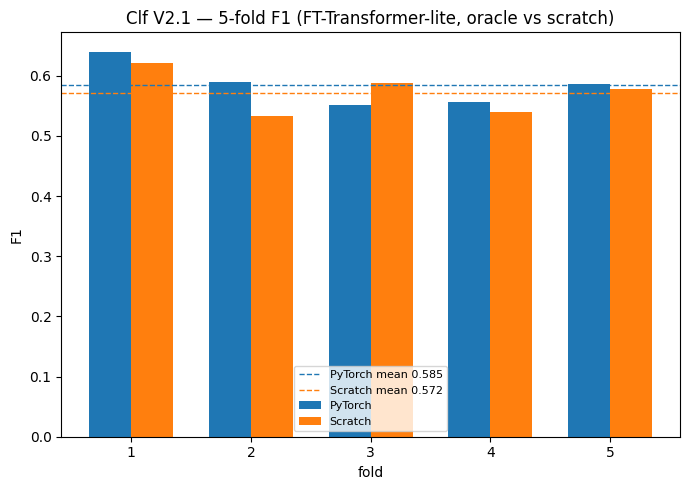

PyTorch F1 mean+-std: 0.5845 0.0352
Scratch F1 mean+-std: 0.572 0.0363

single-split V2.0 oracle F1 (reference): 0.6038


In [6]:
import matplotlib.pyplot as plt

pyt_kf = json.load(open("weights_V2_1/classification_pytorch_kfold_metrics.json"))
scr_kf = json.load(open("weights_V2_1/classification_scratch_kfold_metrics.json"))
pyt_f1 = [r["f1"] for r in pyt_kf["folds"]]
scr_f1 = [r["f1"] for r in scr_kf["folds"]]
folds_x = np.arange(1, K + 1)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, pyt_f1, width, label="PyTorch")
plt.bar(folds_x + width / 2, scr_f1, width, label="Scratch")
plt.axhline(pyt_kf["summary"]["f1"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"PyTorch mean {pyt_kf['summary']['f1']['mean']:.3f}")
plt.axhline(scr_kf["summary"]["f1"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean {scr_kf['summary']['f1']['mean']:.3f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("F1")
plt.title("Clf V2.1 — 5-fold F1 (FT-Transformer-lite, oracle vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_clf_V2_1.png", dpi=150)
plt.show()

print("PyTorch F1 mean+-std:", pyt_kf["summary"]["f1"]["mean"], pyt_kf["summary"]["f1"]["std"])
print("Scratch F1 mean+-std:", scr_kf["summary"]["f1"]["mean"], scr_kf["summary"]["f1"]["std"])

lib_ora = json.load(open("weights_V2_0/classification_pytorch_test_metrics.json"))
print("\nsingle-split V2.0 oracle F1 (reference):", lib_ora["f1"])